## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
    .collect(engine="streaming")
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("total_imbalance_qty") * pl.col("entry_price"))
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("signed_dollar_imbalance") / pl.col("ADV"))
            .clip(-1,1)
        ).alias("signed_mean_imb_ratio"),
        (
            (pl.col("signed_dollar_imbalance") / pl.col("dollar_imbalance").mean().over(pl.col("date")))
        ).alias("signed_cross_imb_ratio"),
        # (
        #     ((pl.col("dollar_imbalance").rank().over(pl.col("date")) - pl.col("dollar_imbalance").rank().mean().over(pl.col("date"))) / pl.col("dollar_imbalance").rank().std().over(pl.col("date")))
        #     *pl.col("sign")
        # ).alias("zscore_rank_imb"),
        (
            ((pl.col("signed_dollar_imbalance").rank().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))) 
             / (pl.col("signed_dollar_imbalance").rank().max().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("zscore_rank_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
)

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,ADV,dollar_imbalance,sign,signed_dollar_imbalance,signed_mean_imb_ratio,signed_cross_imb_ratio,zscore_rank_imb,return_to_close
date,cat,str,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64
2025-06-11,"""AAPL""","""A""",198.81,0.000201,203.23,2.2199e9,5.4598e7,-1,-5.4598e7,-0.024595,-2.344149,-0.761905,0.022232
2025-06-11,"""ADBE""","""B""",412.64,0.000291,415.2,2.5565e8,3.1600e6,1,3.1600e6,0.012361,0.135673,0.47619,0.006204
2025-06-11,"""AMAT""","""A""",171.91,0.000582,174.0,2.2650e8,1.6353e7,-1,-1.6353e7,-0.072197,-0.702106,-0.285714,0.012158
2025-06-11,"""AMD""","""A""",120.83,0.000166,124.42,7.6475e8,3.0765e6,-1,-3.0765e6,-0.004023,-0.132086,0.095238,0.029711
2025-06-11,"""AMZN""","""A""",213.29,0.000094,217.32,1.4141e9,5.7679e7,-1,-5.7679e7,-0.040789,-2.476411,-0.809524,0.018894
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""TMUS""","""B""",184.89,0.000433,181.7,1.9199e8,9.1338e6,1,9.1338e6,0.047574,0.158345,0.512195,-0.017254
2026-06-10,"""TQQQ""","""B""",69.73,0.000143,71.7,1.4516e9,1.6271e7,1,1.6271e7,0.011209,0.282082,0.658537,0.028252
2026-06-10,"""TSLA""","""B""",382.17,0.000052,391.11,3.2056e9,2.5934e7,1,2.5934e7,0.00809,0.449592,0.804878,0.023393


### Working on Forecasting

In [13]:
import sklearn
import statsmodels.api as sm

features = ["signed_mean_imb_ratio", "zscore_rank_imb"]

X = data[features].to_pandas()
y = data["return_to_close"].to_pandas()

model = sklearn.linear_model.Ridge(alpha=0.01)
model.fit(X,y)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.01
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [14]:
print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f"{f} = {model.coef_[i]:,.10f}")

Model coefficients:

signed_mean_imb_ratio = -0.0000195523
zscore_rank_imb = 0.0003861310


Background dataset has 10959 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10959 when initializing the masker.


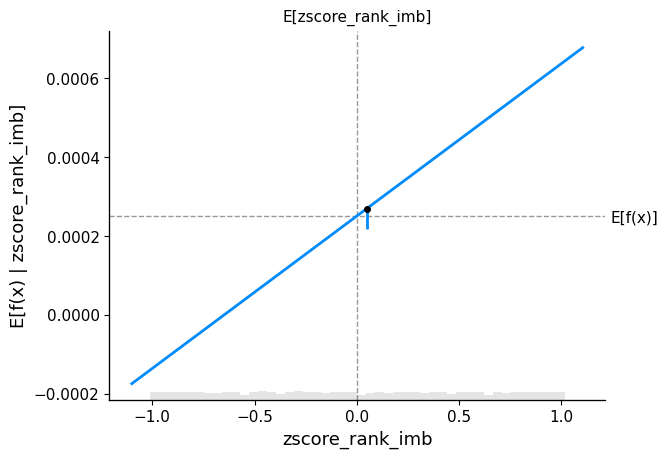

In [15]:
import shap

# compute the SHAP values for the linear model
explainer = shap.Explainer(model.predict, X)
shap_values = explainer(X)

# make a standard partial dependence plot
sample_ind = 20
shap.partial_dependence_plot(
    "zscore_rank_imb",
    model.predict,
    X,
    model_expected_value=True,
    feature_expected_value=True,
    ice=False,
    shap_values=shap_values[sample_ind : sample_ind + 1, :],
)

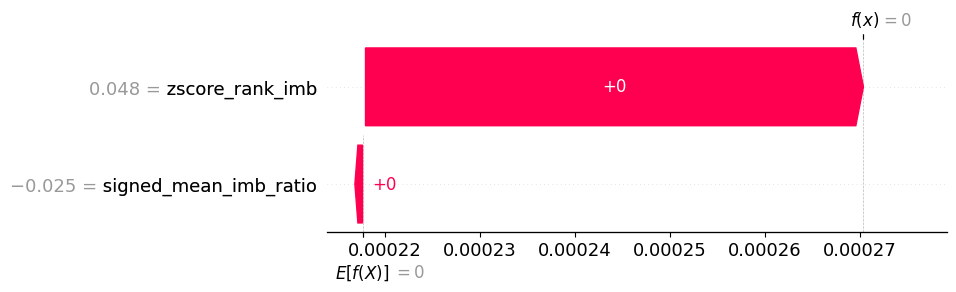

In [16]:
shap.plots.waterfall(shap_values[sample_ind])

### IC Study

In [31]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import spearmanr

# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
features = ["signed_mean_imb_ratio","zscore_rank_imb"]

tscv = TimeSeriesSplit(n_splits=120, max_train_size=120, test_size=1)  # rolling ~120-day train window

fold_ics = []
for i, (train_d, test_d) in enumerate(tscv.split(dates)):
    train_dates = [dates[j] for j in train_d]
    test_dates  = [dates[j] for j in test_d]

    train = data.filter(pl.col("date").is_in(train_dates))
    test  = data.filter(pl.col("date").is_in(test_dates))

    model = Ridge(alpha=1e-1)
    # model = RandomForestRegressor()
    model.fit(train[features].to_numpy(), train["return_to_close"].to_numpy())

    # Forecast on test, then daily cross-sectional rank IC (Spearman), averaged.
    pred = test.with_columns(
        pl.Series("yhat", model.predict(test[features].to_numpy()))
    )
    daily_ic = (
        pred.group_by("date")
        .agg(
            pl.map_groups(
                exprs=["yhat", "return_to_close"],
                function=lambda s: spearmanr(s[0], s[1]).statistic,
                return_dtype=pl.Float64,
                returns_scalar=True,
            ).alias("ic")
        )
        .drop_nulls()
    )
    mean_ic = daily_ic["ic"].mean()
    fold_ics.append(mean_ic)
    print(f"fold {i}: train {train_dates[0]}..{train_dates[-1]} "
          f"({len(train_dates)}d) | test {test_dates[0]}..{test_dates[-1]} "
          f"({len(test_dates)}d) | mean daily IC = {mean_ic:+.4f}")
fold_ics = np.array(fold_ics)
print(f"\nMean IC across folds: {np.mean(fold_ics):+.4f}  "
      f"(IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})")
print(f"Mean IC across Positive IC folds: {np.mean(fold_ics[np.where(fold_ics > 0)]):+.4f}")
print(f"Mean IC across Negative IC folds: {np.mean(fold_ics[np.where(fold_ics < 0)]):+.4f}")

fold 0: train 2025-06-24..2025-12-15 (120d) | test 2025-12-16..2025-12-16 (1d) | mean daily IC = +0.2662
fold 1: train 2025-06-25..2025-12-16 (120d) | test 2025-12-17..2025-12-17 (1d) | mean daily IC = -0.2368
fold 2: train 2025-06-26..2025-12-17 (120d) | test 2025-12-18..2025-12-18 (1d) | mean daily IC = -0.0497
fold 3: train 2025-06-27..2025-12-18 (120d) | test 2025-12-19..2025-12-19 (1d) | mean daily IC = +0.0725
fold 4: train 2025-06-30..2025-12-19 (120d) | test 2025-12-22..2025-12-22 (1d) | mean daily IC = -0.0922
fold 5: train 2025-07-01..2025-12-22 (120d) | test 2025-12-23..2025-12-23 (1d) | mean daily IC = +0.1609
fold 6: train 2025-07-02..2025-12-23 (120d) | test 2025-12-26..2025-12-26 (1d) | mean daily IC = +0.1188
fold 7: train 2025-07-07..2025-12-26 (120d) | test 2025-12-29..2025-12-29 (1d) | mean daily IC = -0.1204
fold 8: train 2025-07-08..2025-12-29 (120d) | test 2025-12-30..2025-12-30 (1d) | mean daily IC = +0.0863
fold 9: train 2025-07-09..2025-12-30 (120d) | test 2025